## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

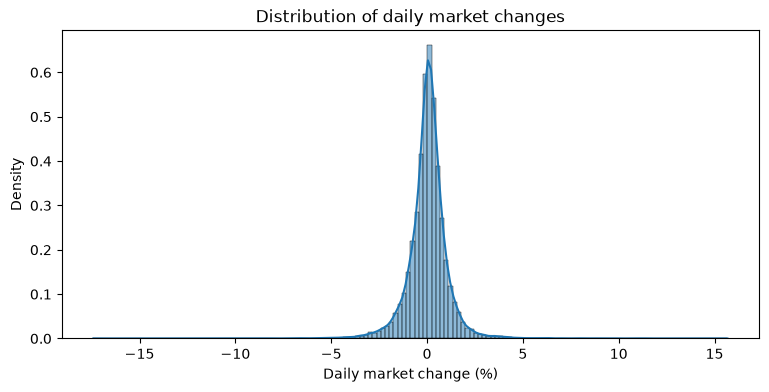

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

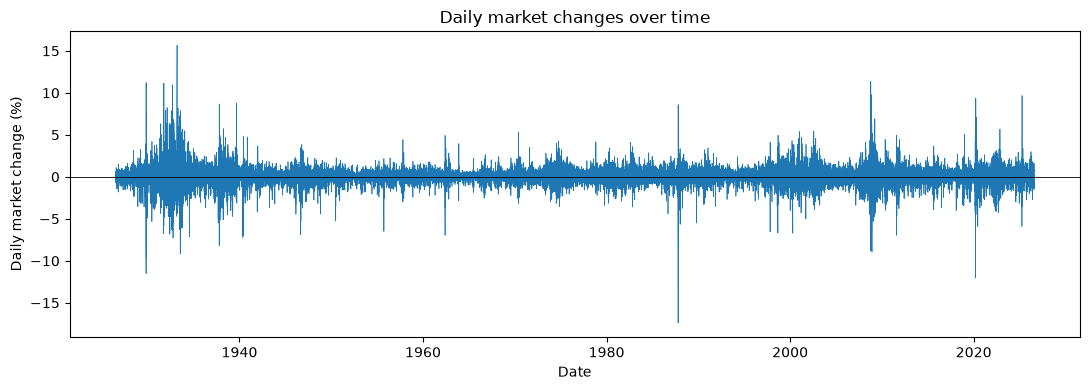

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [8]:
# make a categorical column "direction_t"
df['direction_t'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down')

In [ ]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [ ]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(##TODO ADD CORRECT PD CROSSTAB HERE##,
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

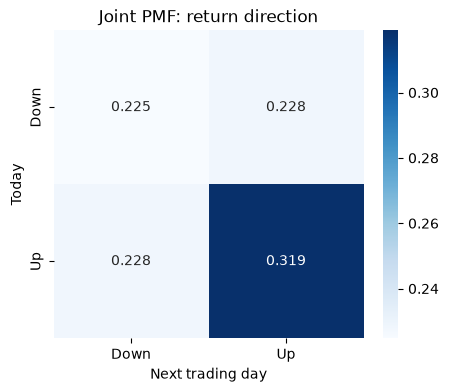

In [33]:
# Plot the joint PMF
joint = pd.crosstab(df['direction_t'], df['direction_tp1'], normalize='all')
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(joint, annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

direction_tp1   Down     Up    All
direction_t                       
Down           0.225  0.228  0.453
Up             0.228  0.319  0.547
All            0.453  0.547  1.000


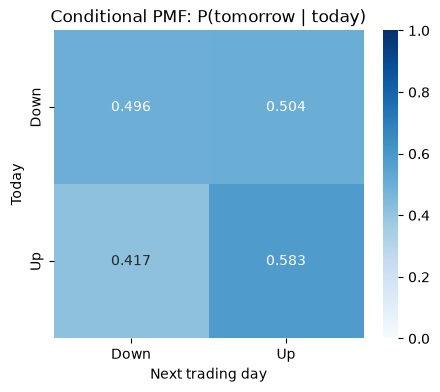

In [7]:
# joint PMF with marginals (the "All" row and column are the marginal PMFs)
joint_m = pd.crosstab(df['direction_t'], df['direction_tp1'], normalize='all', margins=True)
print(joint_m.round(3))

# conditional PMF: P(tomorrow | today). Each row sums to 1
cond = pd.crosstab(df['direction_t'], df['direction_tp1'], normalize='index')

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cond, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: P(tomorrow | today)')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

Up days are more common than down days (54.7% vs. 45.3%). The market is also more likely to be up after an up day than after a down day, so there is mild persistence. 

As shown in the Conditional PMF heatmap, if today is an Up day, there is a 0.583 (58.3%) chance of transitioning to another Up day tomorrow. By contrast, if today is a Down day, the probability of transitioning to an Up day tomorrow is slightly lower at 0.504 (50.4%).

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [10]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'],
                          bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
                          labels=return_categories)   # right=True by default, so upper endpoints are included

In [11]:
#make y_t and y_tp1 columns for the return bins

df['y_t'] = df['return_bin']
df['y_tp1'] = df['y_t'].shift(-1)

<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

In [44]:
# Count the number of days for each value of y_t
df['y_t'].value_counts(sort=False).to_frame(name='No. of Days')

,No. of Days
y_t,
Q1,1255
Q2,1253
Q3,1286
Q4,1280
Q5,1230
Q6,1226
Q7,1371
Q8,1206
Q9,1198


- Small gain is the most common bin (37.2%), followed by Small loss (28.3%). Large loss is the least common (10.5%), with Large gain just behind it in count (10.9%).

In [14]:
#joint PMF with marginals
joint_m = pd.crosstab(df['y_t'], df['y_tp1'], normalize='all', margins=True)
print(joint_m.round(3))

y_tp1       Large loss  Small loss  Near zero  Small gain  Large gain    All
y_t                                                                         
Large loss       0.021       0.027      0.009       0.028       0.020  0.105
Small loss       0.035       0.089      0.034       0.098       0.027  0.283
Near zero        0.009       0.042      0.021       0.049       0.009  0.131
Small gain       0.025       0.100      0.055       0.159       0.033  0.372
Large gain       0.014       0.026      0.012       0.038       0.020  0.109
All              0.105       0.283      0.131       0.372       0.109  1.000


<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

Small gain → Small gain is by far the most likely at about 16% of all day pairs

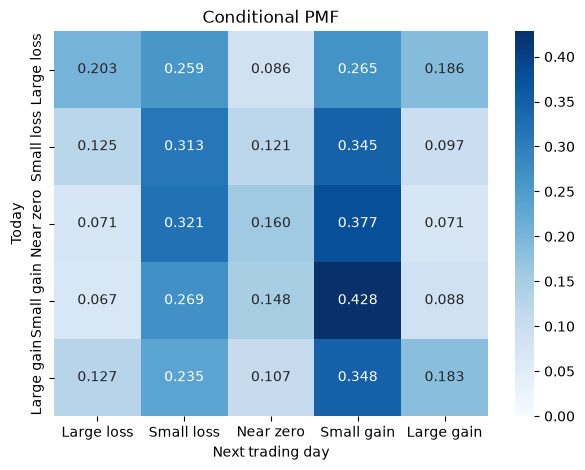

In [15]:
#conditional PMF 
cond = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cond, annot=True, fmt='.3f', cmap='Blues', vmin=0, ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

In [16]:
cond.apply(lambda r: r.nlargest(2).index.tolist(), axis=1)

y_t
Large loss    [Small gain, Small loss]
Small loss    [Small gain, Small loss]
Near zero     [Small gain, Small loss]
Small gain    [Small gain, Small loss]
Large gain    [Small gain, Small loss]
dtype: object

In [ ]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = #TODO: ADD CODE HERE

# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0

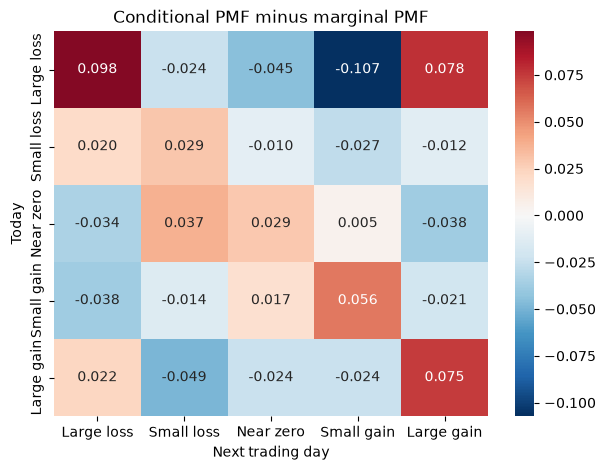

In [17]:
joint = pd.crosstab(df['y_t'], df['y_tp1'], normalize='all')
next_state_pmf = joint.sum(axis=0)

diff = cond.sub(next_state_pmf, axis='columns')

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(diff, annot=True, fmt='.3f', cmap='RdBu_r', center=0, ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF minus marginal PMF')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

- The diagonal is above independence in every row (Large loss → Large loss +0.098, Small loss → Small loss +0.029, Near zero → Near zero +0.029, Small gain → Small gain +0.056, Large gain → Large gain +0.075), so each state tends to be followed by the same state.  

- After a large move, the calm outcomes are much less likely. Large loss is followed by Small gain far less often than independence predicts (-0.107) and by Near zero less often (-0.045). Large gain is followed by Small loss less often (-0.049). Near zero is followed by either large state less often (-0.034 and -0.038), and Small gain is followed by Large loss less often (-0.038).

- Yes, somewhat. If the states were independent, every cell would be near zero

In [18]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('y_t', observed=True)['market_return_pct_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


• The expected percent return for each state is represented by its mean:
	• Large loss: -0.0383%
	• Small loss: -0.0438%
	• Near zero: +0.0150%
	• Small gain: +0.1068%
	• Large gain: +0.1631%

. Large loss has the highest standard deviation at 1.720570.

• Minimum values: The most extreme negative return occurs in the Large loss state (-17.41%), while the least extreme negative minimum is in the Near zero state (-8.19%).
• Maximum values: The highest positive return occurs in the Large gain state (15.67%), while the lowest maximum value is in the Near zero state (5.49%).

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [19]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


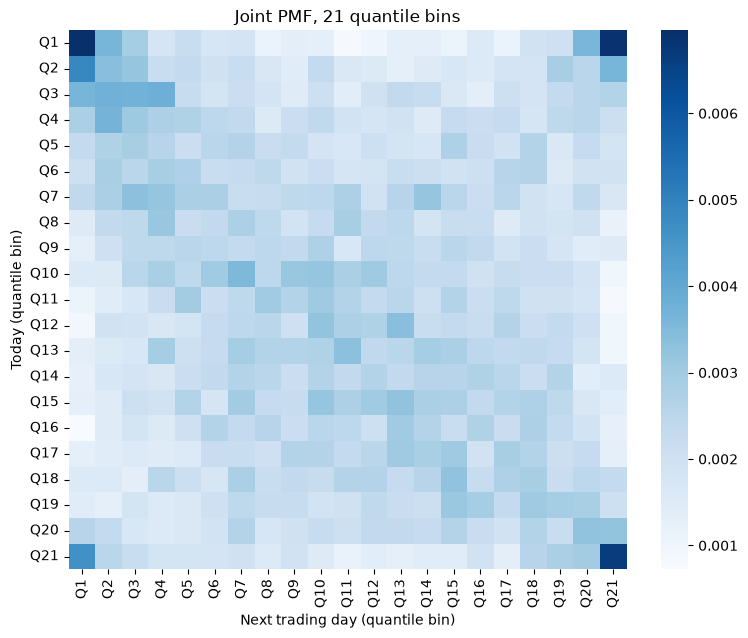

In [20]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap

joint_m = pd.crosstab(df['y_t'], df['y_tp1'], normalize='all', margins=True)
joint = joint_m.iloc[:-1, :-1]   # drop the "All" row and column for plotting

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(joint, cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day (quantile bin)', ylabel='Today (quantile bin)', title='Joint PMF, 21 quantile bins')
plt.show()

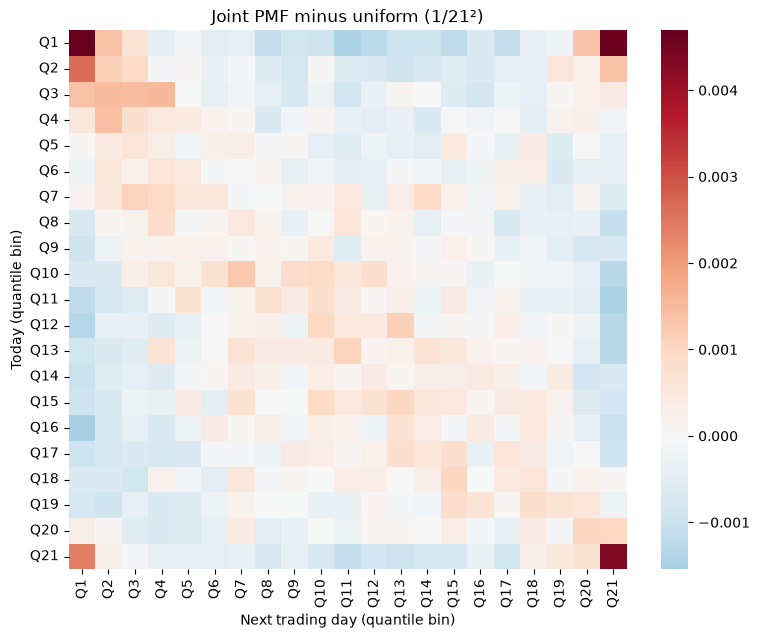

In [21]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(joint - 1/21**2, cmap='RdBu_r', center=0, ax=ax)
ax.set(xlabel='Next trading day (quantile bin)', ylabel='Today (quantile bin)', title='Joint PMF minus uniform (1/21²)')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

- The red squares along the diagonal indicate that the joint probability of consecutive same-state transitions is higher than what absolute randomness (uniform independence) predicts. If today is a severe down day \((Q_1)\), tomorrow is highly likely to also be a severe down day.

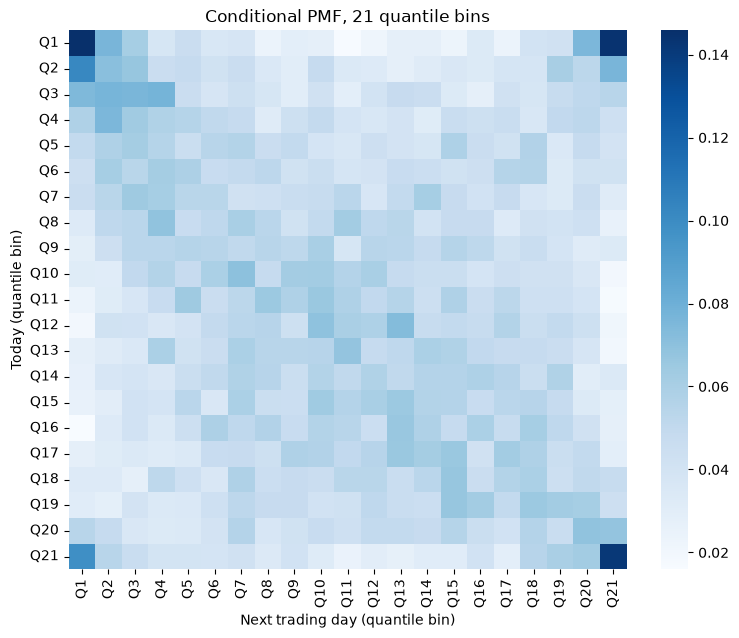

In [26]:
# compute and plot the conditional

cond = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cond, cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day (quantile bin)', ylabel='Today (quantile bin)', title='Conditional PMF, 21 quantile bins')
plt.show()

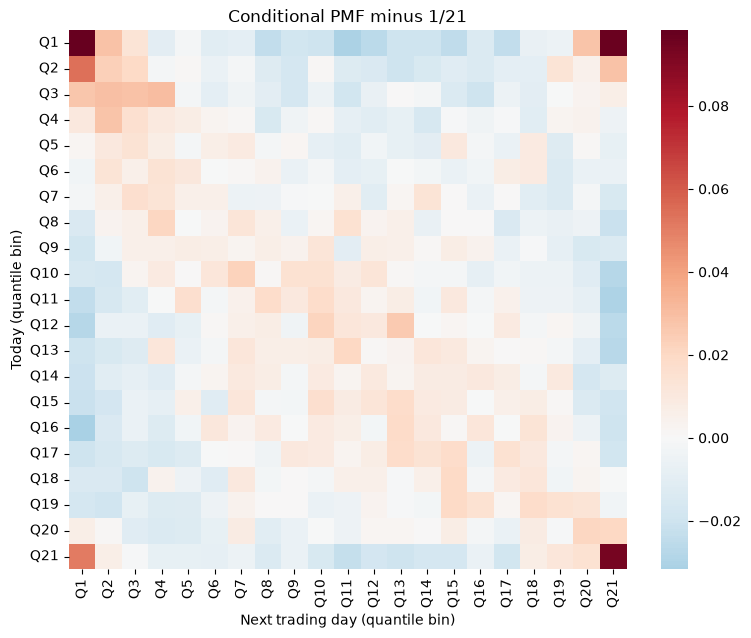

In [25]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cond - 1/21, cmap='RdBu_r', center=0, ax=ax)
ax.set(xlabel='Next trading day (quantile bin)', ylabel='Today (quantile bin)', title='Conditional PMF minus 1/21')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

The conditional PMFs are close to uniform for the middle bins, but the extremes stand out. After the worst and best days, the next day is also an extreme day (in either direction) about three times as often as chance (about 14% vs. 4.8%). After ordinary days, extreme days are less likely than chance. So today’s size predicts the size of tomorrow’s move (volatility clustering), with the effect strongest after large losses, but the direction of tomorrow’s move is still hard to predict.

In [29]:
# compute the next day's min, mean, and max conditional on each bin

stats = df.groupby('y_t', observed=True)['market_return_pct_tp1'].agg(['min', 'mean', 'max', 'std'])
stats



,min,mean,max,std
y_t,,,,
Q1,-17.41,-0.013713,11.22,2.140465
Q2,-7.36,-0.076712,6.36,1.285882
Q3,-8.79,-0.097084,11.36,1.227976
Q4,-8.28,-0.058594,6.16,1.049607
Q5,-6.89,-0.024211,4.56,0.989470
Q6,-11.23,-0.022692,6.37,1.024761
Q7,-3.94,-0.030241,7.37,0.930389
Q8,-3.40,-0.014303,4.76,0.835663
Q9,-6.00,0.025860,5.49,0.853220


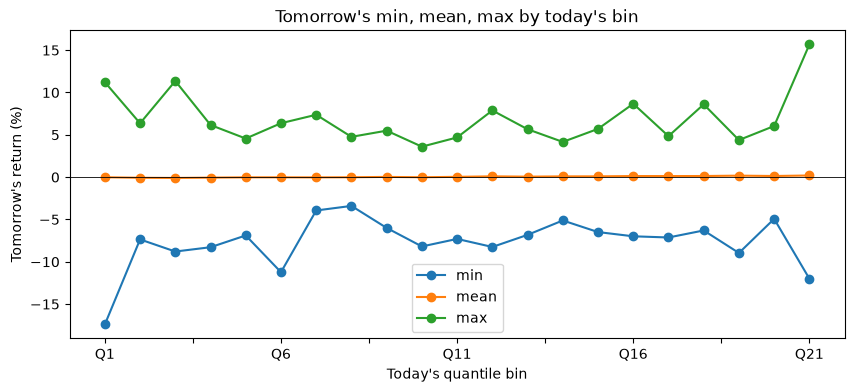

In [30]:
#plot as lines on a graph against the bins

fig, ax = plt.subplots(figsize=(10, 4))
stats[['min', 'mean', 'max']].plot(ax=ax, marker='o')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel="Today's quantile bin", ylabel="Tomorrow's return (%)", title="Tomorrow's min, mean, max by today's bin")
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

The mean of tomorrow’s return is close to 0% for every bin, with a slight upward drift for higher bins, so today’s bin tells us little about the expected direction. The min and max are widest after the most extreme days (Q1 and Q21) and narrowest after middling days (around Q8 to Q10), which suggests larger swings follow large moves in either direction.

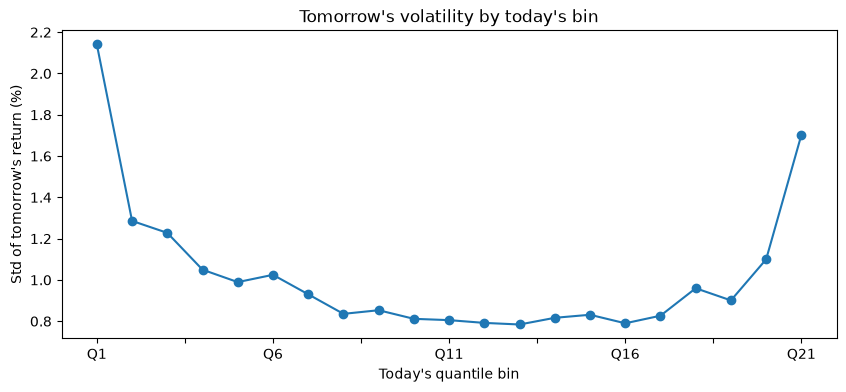

In [31]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 

fig, ax = plt.subplots(figsize=(10, 4))
stats['std'].plot(ax=ax, marker='o')
ax.set(xlabel="Today's quantile bin", ylabel="Std of tomorrow's return (%)", title="Tomorrow's volatility by today's bin")
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

The plot shows a clear volatility pattern, and this time and it is a U shape.
Tomorrow’s standard deviation is highest after the most extreme days. It is about 2.14% after Q1 (the worst days) and about 1.7% after Q21 (the best days). It drops quickly through Q2 to Q5 (about 1.3 down to 1.0), then flattens at its lowest level, around 0.8%, from roughly Q8 through Q17. After that it climbs again through Q18 to Q21.

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

The market is hard to predict. Today’s return tells us almost nothing about whether tomorrow will be up or down, since tomorrow’s average return is close to 0% in every bin. We can only forecast how big the move might be: after extreme days, the next day tends to be much more volatile.